In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ============================================================
# Archetypal Analysis - Mørup & Hansen (2012)
# ============================================================
#
# Convención de este archivo:
#
#   X : (N, M)
#       N observaciones, M variables/features.
#
# El artículo usa las observaciones como COLUMNAS:
#
#   X_art : (M, N)
#
# Por tanto, en nuestra convención:
#
#   C : (D, N)       -> coeficientes que definen los arquetipos
#   S : (N, D)       -> coeficientes que representan las observaciones
#
# Los arquetipos son:
#
#   Z = C @ X      -> (D, M)
#
# y la reconstrucción es:
#
#   X_hat = S @ Z
#         = S @ C @ X -> (N, M)
#
# que es exactamente la transpuesta de:
#
#   X_art @ C @ S
#
# del artículo.
#
# Las restricciones son:
#
#   C >= 0,     sum_n C[n,d] = 1  para cada d
#   S >= 0,     sum_d S[d,n] = 1  para cada n
#
# ============================================================

In [4]:
# ============================================================
# 1. FURTHESTSUM
# ============================================================

def furthest_sum(X, D, rng=None):
    """
    FURTHESTSUM de Mørup & Hansen (2012).

    X tiene forma (N, M): observaciones en filas.

    Devuelve D índices de observaciones candidatas para inicializar C.
    """

    X = np.asarray(X, dtype=float)

    if X.ndim != 2:
        raise ValueError("X debe ser una matriz 2D.")

    N, M = X.shape

    if D < 1:
        raise ValueError("D debe ser >= 1.")

    if D > N:
        raise ValueError(
            "D no puede ser mayor que el número de observaciones."
        )

    if rng is None:
        rng = np.random.default_rng()

    # Paso 1 del Algorithm 1:
    # elegir una observación aleatoria.
    j = int(rng.integers(N))
    selected = [j]

    # q_i = ||x_i - x_j||_F
    q = np.linalg.norm(X - X[j], axis=1)

    # q_hat = q
    q_hat = q.copy()

    # El algoritmo añade D puntos y después elimina
    # el primer punto aleatorio.
    for t in range(1, D + 1):

        if t == D:
            q = q - q_hat

        available = np.ones(N, dtype=bool)
        available[selected] = False

        j = int(np.argmax(np.where(available, q, -np.inf)))
        selected.append(j)

        distances = np.linalg.norm(X - X[j], axis=1)
        q = q + distances

    # El primer punto aleatorio se elimina.
    # Esto implementa literalmente la observación del artículo:
    # "the first point selected by random is removed".
    return np.asarray(selected[1:], dtype=int)

In [5]:
# Funciones auxiliares para la normalización y el cálculo de gradientes
# ============================================================
# 2. NORMALIZACIÓN
# ============================================================

def normalize_rows(A):
    """
    Normaliza cada fila de A para que sume 1.

    Parámetros
    ----------
    A : np.ndarray
        Matriz de pesos.

    Returns
    -------
    np.ndarray
        Matriz con cada fila normalizada.
    """
    A = np.asarray(A, dtype=float)

    row_sums = A.sum(axis=1, keepdims=True)

    # Evitar divisiones por cero
    row_sums[row_sums == 0] = 1.0

    return A / row_sums

In [6]:
# Función objetivo y gradientes para la actualización de C y S
# ============================================================
# 3. FUNCIÓN OBJETIVO
# ============================================================

def aa_objective(X, C, S):
    """
    Objetivo de Archetypal Analysis:

        ||X - X_art C S||_F^2

    expresado con X en filas:

        ||X - S.T C.T X||_F^2
    """

    X_hat = S @ C @ X
    residual = X - X_hat

    return np.sum(residual ** 2)

In [7]:
# ============================================================
# 4. GRADIENTE RESPECTO DE S
# ============================================================

def gradient_S(XTX, C, S):
    """
    Gradiente normalizado respecto de S.

    El artículo, usando observaciones como columnas, da:

        G_S =
            S C X X.T C.T
            - X X.T C.T 

    donde aquí:

        XTX = X_art.T X_art
            = X @ X.T

    Después se utiliza la corrección de invariancia a la
    normalización descrita en el artículo:

        G_tilde[d,n] =
            G[d,n]
            - sum_d' G[d',n] S[d',n]

    """

    # Gradiente indicado en el artículo
    G = S @ C @ XTX @ C.T 
    G -= XTX @ C.T

    # Corrección de invariancia de normalización
    correction = np.sum(
        G * S,
        axis=1,
        keepdims=True
    )

    G_tilde = G - correction

    return G_tilde


In [8]:
# ============================================================
# 5. GRADIENTE RESPECTO DE C
# ============================================================

def gradient_C(XTX, C, S):
    """
    Gradiente normalizado respecto de C.

    El artículo da:

        G_C =
            S.T S C X X.T
            - S.T X X.T

    """

    # X.T X C S S.T
    G = S.T @ S @ C @ XTX
    G -= S.T @ XTX

    # Corrección de invariancia de normalización
    correction = np.sum(
        G * C,
        axis=1,
        keepdims=True
    )

    G_tilde = G - correction

    return G_tilde


In [9]:
# ============================================================
# 6. ACTUALIZACIÓN PROYECTADA DE S
# ============================================================

def update_S(XTX, C, S, step):
    """
    Una actualización projected-gradient de S.

    El artículo utiliza:

        S_new =
            max(
                S - step * G_tilde_S,
                0
            )

    seguida de la normalización L1.
    """

    G = gradient_S(XTX, C, S)

    S_new = S - step * G

    # Proyección sobre el ortante no negativo
    S_new = np.maximum(S_new, 0.0)

    # Normalización para imponer sum_d S[d,n] = 1
    S_new = normalize_rows(S_new)

    return S_new

In [10]:
# ============================================================
# 7. ACTUALIZACIÓN PROYECTADA DE C
# ============================================================

def update_C(XTX, C, S, step):
    """
    Una actualización projected-gradient de C.
    """

    G = gradient_C(XTX, C, S)

    C_new = C - step * G

    # No negatividad
    C_new = np.maximum(C_new, 0.0)

    # sum_n C[n,d] = 1
    C_new = normalize_rows(C_new)

    return C_new


In [11]:
# ============================================================
# 8. LINE SEARCH PARA S
# ============================================================

def line_search_S(
    X,
    XTX,
    C,
    S,
    initial_step=1.0,
    max_search=10
):
    """
    Line search por backtracking.

    El artículo especifica que el tamaño de paso se ajusta
    mediante line-search y que se realizan 10 line-search
    updates por actualización alternante.

    El artículo NO especifica la regla exacta de backtracking.
    Por ello usamos aquí la regla estándar de dividir el paso
    por 2 hasta encontrar una mejora.
    """

    current_loss = aa_objective(X, C, S)

    step = initial_step

    for _ in range(max_search):

        candidate = update_S(
            XTX,
            C,
            S,
            step
        )

        candidate_loss = aa_objective(
            X,
            C,
            candidate
        )

        if candidate_loss < current_loss:
            return candidate, step, candidate_loss

        step *= 0.5

    # Si ningún paso mejora la función, mantenemos S.
    return S.copy(), step, current_loss


In [12]:
# ============================================================
# 9. LINE SEARCH PARA C
# ============================================================

def line_search_C(
    X,
    XTX,
    C,
    S,
    initial_step=1.0,
    max_search=10
):
    """
    Line search por backtracking para C.
    """

    current_loss = aa_objective(X, C, S)

    step = initial_step

    for _ in range(max_search):

        candidate = update_C(
            XTX,
            C,
            S,
            step
        )

        candidate_loss = aa_objective(
            X,
            candidate,
            S
        )

        if candidate_loss < current_loss:
            return candidate, step, candidate_loss

        step *= 0.5

    return C.copy(), step, current_loss

In [13]:
# ============================================================
# 10. INICIALIZACIÓN DE C
# ============================================================

def initialize_C(X, D, rng):
    """
    Inicializa C mediante FURTHESTSUM.

    Cada arquetipo comienza siendo exactamente una observación:

        C[d, index] = 1
    """

    selected = furthest_sum(
        X,
        D,
        rng=rng
    )

    N = X.shape[0]

    C = np.zeros((D, N), dtype=float)

    for d, index in enumerate(selected):
        C[d, index] = 1.0

    return C, selected


In [14]:
# ============================================================
# 11. INICIALIZACIÓN DE S
# ============================================================

def initialize_S(N, D, rng):
    """
    Inicialización aleatoria de S y normalización por filas.
    """

    S = rng.random((N, D))

    return normalize_rows(S)

In [15]:
# ============================================================
# 12. ARQUETIPOS
# ============================================================

def compute_archetypes(X, C):
    """
    Calcula los arquetipos:

        Z = C @ X

    Z tiene forma (D, M).
    """

    return C @ X

In [16]:
# ============================================================
# 13. GRADIENT CHECK
# ============================================================

def check_gradients(
    X,
    C,
    S,
    epsilon=1e-6
):
    """
    Comprueba numéricamente que las expresiones analíticas
    del gradiente coinciden con derivadas por diferencias finitas.

    Se compara el gradiente sin el factor 2.

    La derivada real del objetivo ||...||² contiene un factor 2,
    mientras que las ecuaciones del artículo omiten ese factor,
    que queda absorbido por el tamaño del paso.
    """

    XTX = X @ X.T

    Gs = gradient_S(XTX, C, S)
    Gc = gradient_C(XTX, C, S)

    # Para comprobar la derivada matemática completa usamos
    # 2 * gradiente. La corrección de normalización NO forma
    # parte de la derivada euclídea simple; por ello para esta
    # prueba comprobamos primero el gradiente base.
    Gs_base = S @ C @ XTX @ C.T - XTX @ C.T
    Gc_base = S.T @ S @ C @ XTX - S.T @ XTX

    # ---- S ----
    i_s, j_s = 0, 0

    S_plus = S.copy()
    S_minus = S.copy()

    S_plus[i_s, j_s] += epsilon
    S_minus[i_s, j_s] -= epsilon

    numerical_S = (
        aa_objective(X, C, S_plus)
        - aa_objective(X, C, S_minus)
    ) / (2 * epsilon)

    analytical_S = 2 * Gs_base[i_s, j_s]

    # ---- C ----
    i_c, j_c = 0, 0

    C_plus = C.copy()
    C_minus = C.copy()

    C_plus[i_c, j_c] += epsilon
    C_minus[i_c, j_c] -= epsilon

    numerical_C = (
        aa_objective(X, C_plus, S)
        - aa_objective(X, C_minus, S)
    ) / (2 * epsilon)

    analytical_C = 2 * Gc_base[i_c, j_c]

    print("\n" + "=" * 60)
    print("COMPROBACIÓN NUMÉRICA DE LOS GRADIENTES")
    print("=" * 60)

    print("\nS:")
    print("  derivada numérica :", numerical_S)
    print("  derivada analítica:", analytical_S)
    print(
        "  error absoluto    :",
        abs(numerical_S - analytical_S)
    )

    print("\nC:")
    print("  derivada numérica :", numerical_C)
    print("  derivada analítica:", analytical_C)
    print(
        "  error absoluto    :",
        abs(numerical_C - analytical_C)
    )

    # Variables Gs/Gc se calculan para asegurar que las funciones
    # de gradiente completas son ejecutables.
    _ = Gs, Gc

In [17]:
# ============================================================
# 14. ARQUETYPAL ANALYSIS
# ============================================================

def archetypal_analysis(
    X,
    p,
    max_iter=100,
    max_inner_iter=10,
    tol=1e-6,
    random_state=42,
    initial_step_S=1.0,
    initial_step_C=1.0,
    line_search_steps=10,
    verbose=True
):
    """
    Archetypal Analysis mediante el projected gradient de
    Mørup & Hansen (2012).

    Parámetros
    ----------
    X : ndarray, shape (N, M)
        Datos con observaciones en filas.

    p : int
        Número de arquetipos.

    max_iter : int
        Número máximo de actualizaciones alternantes.

    max_inner_iter : int
        Número de line-search updates iniciales de S.

    tol : float
        Tolerancia relativa de convergencia.

    random_state : int, Generator o None
        Semilla/generador.

    initial_step_S : float
        Paso inicial para S.

    initial_step_C : float
        Paso inicial para C.

    line_search_steps : int
        Número de intentos del backtracking.
    verbose : bool
        Mostrar la evolución de la función objetivo.

    Returns
    -------
    A : ndarray, shape (N, p)
        Matriz C del artículo.

    B : ndarray, shape (p, N)
        Matriz S del artículo.

    Z : ndarray, shape (p, M)
        Arquetipos.

    history : ndarray
        Historial del objetivo.

    selected : ndarray
        Observaciones iniciales elegidas por FURTHESTSUM.
    """

    X = np.asarray(X, dtype=float)

    if X.ndim != 2:
        raise ValueError("X debe ser una matriz 2D.")

    N, M = X.shape

    if p < 1:
        raise ValueError("p debe ser >= 1.")

    if p > N:
        raise ValueError(
            "p no puede ser mayor que el número de observaciones."
        )

    if random_state is None:
        rng = np.random.default_rng()
    elif isinstance(random_state, (int, np.integer)):
        rng = np.random.default_rng(random_state)
    else:
        rng = random_state

    # --------------------------------------------------------
    # Precomputación
    #
    # En la notación del artículo:
    #
    #   X_art.T @ X_art
    #
    # Como aquí X está en filas:
    #
    #   X @ X.T
    # --------------------------------------------------------

    XTX = X @ X.T

    # --------------------------------------------------------
    # Inicializar C mediante FURTHESTSUM
    # --------------------------------------------------------

    C, selected = initialize_C(
        X,
        p,
        rng
    )

    # --------------------------------------------------------
    # Inicializar S aleatoriamente
    # --------------------------------------------------------

    S = initialize_S(
        N,
        p,
        rng
    )

    for _ in range(max_inner_iter):

        S_new, initial_step_S, _ = line_search_S(
            X,
            XTX,
            C,
            S,
            initial_step=initial_step_S,
            max_search=line_search_steps
        )

        S = S_new

    # --------------------------------------------------------
    # Objetivo inicial
    # --------------------------------------------------------

    current_loss = aa_objective(X, C, S)

    history = [current_loss]

    if verbose:
        print("=" * 70)
        print("ARCHETYPAL ANALYSIS - PROJECTED GRADIENT - SCX")
        print("=" * 70)
        print(f"N observaciones : {N}")
        print(f"M variables     : {M}")
        print(f"D arquetipos    : {p}")
        print(f"Loss inicial    : {current_loss:.8e}")
        print(f"FURTHESTSUM     : {selected}")
        print()

    # --------------------------------------------------------
    # Optimización alternante
    # --------------------------------------------------------

    for iteration in range(max_iter):

        # ====================================================
        # Actualizar S
        # ====================================================

        S_new, initial_step_S, loss_S = line_search_S(
            X,
            XTX,
            C,
            S,
            initial_step=initial_step_S,
            max_search=line_search_steps
        )

        S = S_new

        # ====================================================
        # Actualizar C
        # ====================================================

        C_new, initial_step_C, loss_C = line_search_C(
            X,
            XTX,
            C,
            S,
            initial_step=initial_step_C,
            max_search=line_search_steps
        )

        C = C_new

        # ====================================================
        # Objetivo
        # ====================================================

        loss = aa_objective(X, C, S)

        history.append(loss)

        relative_change = (
            abs(current_loss - loss)
            / max(abs(current_loss), 1e-16)
        )

        if verbose:
            print(
                f"Iteración {iteration + 1:4d} | "
                f"Loss = {loss:.8e} | "
                f"cambio relativo = {relative_change:.3e} | "
                f"step_S = {initial_step_S:.3e} | "
                f"step_C = {initial_step_C:.3e}"
            )

        if relative_change < tol:
            break

        current_loss = loss

    # --------------------------------------------------------
    # Arquetipos finales
    # --------------------------------------------------------

    Z = compute_archetypes(X, C)

    return C, S, Z, np.asarray(history), selected


In [18]:
# ============================================================
# 16. WEIGHTED ARCHETYPAL ANALYSIS
# ============================================================
# Weighted objective from the paper:
#     RSS_W = || W (X - S C X) ||_F^2
# For diagonal W=diag(weights), the efficient observation-space
# Gram matrix is K = X W^2 X.T = (W X)(W X).T.
# The final archetypes remain Z = C @ X using the ORIGINAL X.
# ============================================================

In [19]:
def validate_weights(weights, N):
    if weights is None:
        return np.ones(N, dtype=float)
    w = np.asarray(weights, dtype=float)
    if w.ndim != 1 or len(w) != N:
        raise ValueError(f"weights debe tener forma ({N},).")
    if not np.all(np.isfinite(w)):
        raise ValueError("weights contiene valores no finitos.")
    if np.any(w < 0):
        raise ValueError("weights debe ser no negativo.")
    if not np.any(w > 0):
        raise ValueError("Al menos un peso debe ser estrictamente positivo.")
    return w

In [20]:
def weighted_objective(X, C, S, weights):
    """RSS_W = ||diag(weights) (X - S C X)||_F^2."""
    residual = X - S @ C @ X
    return np.sum((weights[:, None] * residual) ** 2)


In [21]:
def weighted_gram_matrix(X, weights):
    """K = X.T W.T W X, without constructing W."""
    Xw = X * weights[:, None]
    return Xw.T @ Xw

In [22]:
def weighted_observation_gram(X, weights):
    """K = X W.T W X.T = (W X)(W X).T, shape (N,N)."""
    Xw = X * weights[:, None]
    return Xw @ Xw.T

In [23]:
def weighted_gradient_S(K, C, S):
    """Base gradient for S, using K = X.T? See weighted_fit below."""
    G = S @ C @ K @ C.T - K @ C.T
    correction = np.sum(G * S, axis=1, keepdims=True)
    return G - correction

def weighted_gradient_C(K, C, S):
    G = S.T @ S @ C @ K - S.T @ K
    correction = np.sum(G * C, axis=1, keepdims=True)
    return G - correction

In [24]:
def update_weighted_S(K, C, S, step):
    S_new = np.maximum(S - step * weighted_gradient_S(K, C, S), 0.0)
    return normalize_rows(S_new)

def update_weighted_C(K, C, S, step):
    C_new = np.maximum(C - step * weighted_gradient_C(K, C, S), 0.0)
    return normalize_rows(C_new)

In [25]:
def weighted_line_search_S(X, K, C, S, weights, initial_step=1.0, max_search=10):
    current = weighted_objective(X, C, S, weights)
    step = initial_step
    for _ in range(max_search):
        candidate = update_weighted_S(K, C, S, step)
        loss = weighted_objective(X, C, candidate, weights)
        if loss < current:
            return candidate, step, loss
        step *= 0.5
    return S.copy(), step, current


def weighted_line_search_C(X, K, C, S, weights, initial_step=1.0, max_search=10):
    current = weighted_objective(X, C, S, weights)
    step = initial_step
    for _ in range(max_search):
        candidate = update_weighted_C(K, C, S, step)
        loss = weighted_objective(X, candidate, S, weights)
        if loss < current:
            return candidate, step, loss
        step *= 0.5
    return C.copy(), step, current

In [26]:
def weighted_archetypal_analysis(
    X, p, weights=None, max_iter=100, max_inner_iter=10,
    tol=1e-6, random_state=42, initial_step_S=1.0,
    initial_step_C=1.0, line_search_steps=10, verbose=True,
    furthest_sum_func=None, initialize_C_func=None, initialize_S_func=None,
    compute_archetypes_func=None
):
    """Weighted AA preserving the user's (N,M), C=(p,N), S=(N,p) convention.

    The weighted problem is ||W(X-SCX)||_F^2, W=diag(weights).
    Archetpyes are always returned as Z=C@X using the original X.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X debe ser una matriz 2D.")
    N, M = X.shape
    if p < 1 or p > N:
        raise ValueError("p debe cumplir 1 <= p <= N.")
    weights = validate_weights(weights, N)

    rng = (np.random.default_rng() if random_state is None
           else np.random.default_rng(random_state)
           if isinstance(random_state, (int, np.integer)) else random_state)

    # K is the exact weighted analogue of the user's X @ X.T.
    # K = X.T? In the user's row convention the required matrix is
    # X W^2 X.T = (W X)(W X).T.
    K = weighted_observation_gram(X, weights)

    if furthest_sum_func is None or initialize_C_func is None or initialize_S_func is None:
        raise ValueError("Pasa las funciones initialize_C/initialize_S/FURTHESTSUM del archivo original.")

    C, selected = initialize_C_func(X, p, rng)
    S = initialize_S_func(N, p, rng)

    for _ in range(max_inner_iter):
        S, initial_step_S, _ = weighted_line_search_S(
            X, K, C, S, weights, initial_step_S, line_search_steps)

    current_loss = weighted_objective(X, C, S, weights)
    history = [current_loss]

    if verbose:
        print("=" * 70)
        print("WEIGHTED ARCHETYPAL ANALYSIS - PROJECTED GRADIENT")
        print("=" * 70)
        print(f"N observaciones : {N}")
        print(f"M variables     : {M}")
        print(f"D arquetipos    : {p}")
        print(f"Peso mínimo     : {weights.min():.6g}")
        print(f"Peso máximo     : {weights.max():.6g}")
        print(f"Weighted RSS    : {current_loss:.8e}")
        print(f"FURTHESTSUM     : {selected}")

    for iteration in range(max_iter):
        S, initial_step_S, _ = weighted_line_search_S(
            X, K, C, S, weights, initial_step_S, line_search_steps)
        C, initial_step_C, _ = weighted_line_search_C(
            X, K, C, S, weights, initial_step_C, line_search_steps)

        loss = weighted_objective(X, C, S, weights)
        history.append(loss)
        relative_change = abs(current_loss - loss) / max(abs(current_loss), 1e-16)

        if verbose:
            print(f"Iteración {iteration+1:4d} | Weighted RSS = {loss:.8e} | "
                  f"cambio relativo = {relative_change:.3e} | "
                  f"step_S = {initial_step_S:.3e} | step_C = {initial_step_C:.3e}")

        if relative_change < tol:
            break
        current_loss = loss

    Z = C @ X if compute_archetypes_func is None else compute_archetypes_func(X, C)
    return C, S, Z, np.asarray(history), selected, weights

In [ ]:
# ============================================================
# 17. PRUEBA DEL ALGORITMO
# ============================================================

if __name__ == "__main__":

    print("\n" + "=" * 70)
    print("PRUEBA DE WEIGHTED ARCHETYPAL ANALYSIS")
    print("=" * 70)

    # --------------------------------------------------------
    # 1. Crear un dataset de prueba
    # --------------------------------------------------------

    rng = np.random.default_rng(42)

    N = 50       # número de observaciones
    M = 3        # número de variables
    p = 3        # número de arquetipos

    X = rng.normal(size=(N, M))

    # --------------------------------------------------------
    # 2. Definir pesos
    # --------------------------------------------------------
    #
    # Damos más importancia a algunas observaciones y menos
    # importancia a otras.
    # --------------------------------------------------------

    weights = np.ones(N)

    weights[:10] = 2.0
    weights[10:20] = 0.5

    print(f"\nDataset:")
    print(f"  X.shape       = {X.shape}")
    print(f"  p             = {p}")
    print(f"  weights.shape = {weights.shape}")
    print(f"  peso mínimo   = {weights.min()}")
    print(f"  peso máximo   = {weights.max()}")

    # --------------------------------------------------------
    # 3. Ejecutar Weighted Archetypal Analysis
    # --------------------------------------------------------

    C, S, Z, history, selected, weights_out = (
        weighted_archetypal_analysis(
            X=X,
            p=p,
            weights=weights,
            max_iter=50,
            max_inner_iter=10,
            tol=1e-6,
            random_state=42,
            initial_step_S=1.0,
            initial_step_C=1.0,
            line_search_steps=10,
            verbose=True,

            # Funciones del AA original
            furthest_sum_func=furthest_sum,
            initialize_C_func=initialize_C,
            initialize_S_func=initialize_S,
            compute_archetypes_func=compute_archetypes
        )
    )

    # --------------------------------------------------------
    # 4. Comprobar dimensiones
    # --------------------------------------------------------

    assert C.shape == (p, N), (
        f"C tiene forma incorrecta: {C.shape}"
    )

    assert S.shape == (N, p), (
        f"S tiene forma incorrecta: {S.shape}"
    )

    assert Z.shape == (p, M), (
        f"Z tiene forma incorrecta: {Z.shape}"
    )

    assert history.ndim == 1, (
        "history debe ser un vector 1D."
    )

    assert len(selected) == p, (
        "El número de observaciones seleccionadas debe ser p."
    )

    # --------------------------------------------------------
    # 5. Comprobar restricciones de C
    # --------------------------------------------------------

    assert np.all(C >= -1e-12), (
        "C contiene valores negativos."
    )

    assert np.allclose(
        C.sum(axis=1),
        1.0,
        atol=1e-10
    ), (
        "Las filas de C no suman 1."
    )

    # --------------------------------------------------------
    # 6. Comprobar restricciones de S
    # --------------------------------------------------------

    assert np.all(S >= -1e-12), (
        "S contiene valores negativos."
    )

    assert np.allclose(
        S.sum(axis=1),
        1.0,
        atol=1e-10
    ), (
        "Las filas de S no suman 1."
    )

    # --------------------------------------------------------
    # 7. Comprobar pesos
    # --------------------------------------------------------

    assert np.allclose(
        weights_out,
        weights
    ), (
        "Los pesos devueltos no coinciden con los pesos introducidos."
    )

    # --------------------------------------------------------
    # 8. Comprobar los arquetipos
    # --------------------------------------------------------

    Z_expected = C @ X

    assert np.allclose(
        Z,
        Z_expected
    ), (
        "Los arquetipos Z no coinciden con C @ X"
    )

    # --------------------------------------------------------
    # 9. Comprobar la función objetivo
    # --------------------------------------------------------

    initial_loss = history[0]
    final_loss = history[-1]

    assert np.isfinite(initial_loss), (
        "El objetivo inicial no es finito."
    )

    assert np.isfinite(final_loss), (
        "El objetivo final no es finito."
    )

    # El algoritmo utiliza line-search, por lo que el objetivo
    # no debería aumentar.
    assert np.all(
        np.diff(history) <= 1e-10
    ), (
        "El Weighted RSS ha aumentado durante alguna iteración."
    )

    # --------------------------------------------------------
    # 10. Mostrar resultados
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("RESULTADOS DE LA PRUEBA")
    print("=" * 70)

    print(f"\nForma de C : {C.shape}")
    print(f"Forma de S : {S.shape}")
    print(f"Forma de Z : {Z.shape}")

    print(f"\nObservaciones seleccionadas:")
    print(selected)

    print(f"\nLoss inicial:")
    print(f"  {initial_loss:.8e}")

    print(f"\nLoss final:")
    print(f"  {final_loss:.8e}")

    print(f"\nNúmero de iteraciones:")
    print(f"  {len(history) - 1}")

    print("\nSuma de las filas de C:")
    print(C.sum(axis=1))

    print("\nSuma de las filas de S:")
    print(S.sum(axis=1))

    print("\n" + "=" * 70)
    print("✓ TODAS LAS PRUEBAS HAN PASADO CORRECTAMENTE")
    print("=" * 70)


PRUEBA DE WEIGHTED ARCHETYPAL ANALYSIS

Dataset:
  X.shape       = (50, 3)
  p             = 3
  weights.shape = (50,)
  peso mínimo   = 0.5
  peso máximo   = 2.0
WEIGHTED ARCHETYPAL ANALYSIS - PROJECTED GRADIENT
N observaciones : 50
M variables     : 3
D arquetipos    : 3
Peso mínimo     : 0.5
Peso máximo     : 2
Weighted RSS    : 8.39791679e+01
FURTHESTSUM     : [ 1 46 47]
Iteración    1 | Weighted RSS = 7.42909136e+01 | cambio relativo = 1.154e-01 | step_S = 2.711e-20 | step_C = 3.906e-03
Iteración    2 | Weighted RSS = 6.98723626e+01 | cambio relativo = 5.948e-02 | step_S = 2.647e-23 | step_C = 1.953e-03
Iteración    3 | Weighted RSS = 5.91320942e+01 | cambio relativo = 1.537e-01 | step_S = 2.585e-26 | step_C = 1.953e-03
Iteración    4 | Weighted RSS = 5.87977438e+01 | cambio relativo = 5.654e-03 | step_S = 2.524e-29 | step_C = 4.883e-04
Iteración    5 | Weighted RSS = 5.87977438e+01 | cambio relativo = 0.000e+00 | step_S = 2.465e-32 | step_C = 4.768e-07

RESULTADOS DE LA PRUEBA




PRUEBA Y DIBUJO: AA SIN PESOS VS AA CON PESOS (PESOS EXTREMOS)
Dataset generado con 100 muestras.
  - Muestras con peso bajo (izq): 43
  - Muestras con peso alto (der): 6


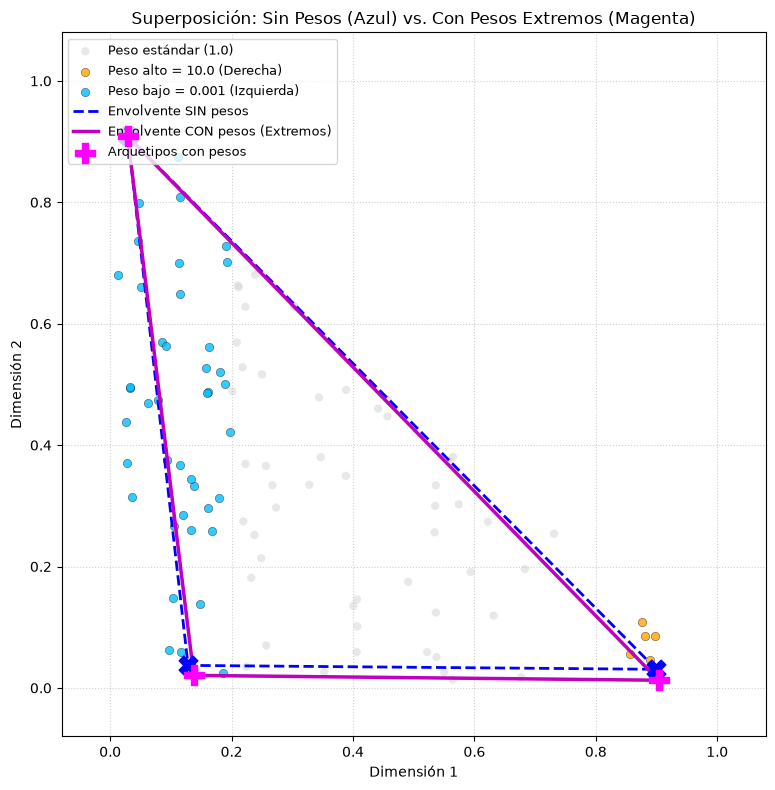


Diferencia máxima entre los arquetipos de ambos métodos: 0.018019712666363995
¡Perfecto! Los arquetipos se han desplazado gracias a los pesos.


<Figure size 640x480 with 0 Axes>


COMPARACIÓN NUMÉRICA
Arquetipos encontrados SIN pesos:
[[0.89972533 0.03070263]
 [0.02894368 0.90875589]
 [0.12834471 0.03711885]]

Arquetipos encontrados CON pesos extremos:
[[0.90356545 0.01268292]
 [0.02894368 0.90875589]
 [0.13779812 0.02064499]]

Diferencia máxima entre arquetipos: 0.018019712666363995


In [40]:
if __name__ == "__main__":

    print("\n" + "=" * 70)
    print("PRUEBA Y DIBUJO: AA SIN PESOS VS AA CON PESOS (PESOS EXTREMOS)")
    print("=" * 70)

    # --------------------------------------------------------
    # 1. Crear datos sintéticos con 3 arquetipos conocidos
    # --------------------------------------------------------
    rng = np.random.default_rng(42)

    true_Z = np.array([
        [0.0, 0.0],
        [1.0, 0.0],
        [0.0, 1.0]
    ])

    n_samples = 100

    true_S = rng.dirichlet(
        np.ones(3),
        size=n_samples
    )

    X = true_S @ true_Z

    # --------------------------------------------------------
    # 2. Definir pesos extremos basados en la posición horizontal
    # --------------------------------------------------------
    weights = np.ones(n_samples)
    
    # Asignar un peso casi nulo a los puntos situados más a la izquierda
    low_weight = X[:, 0] <= 0.2
    weights[low_weight] = 0.001  

    # Asignar un peso muy alto a los puntos situados más a la derecha
    high_weight = X[:, 0] > 0.8
    weights[high_weight] = 10.0   

    print(f"Dataset generado con {n_samples} muestras.")
    print(f"  - Muestras con peso bajo (izq): {np.sum(low_weight)}")
    print(f"  - Muestras con peso alto (der): {np.sum(high_weight)}")

    # --------------------------------------------------------
    # 3. Ejecutar AA SIN PESOS
    # --------------------------------------------------------
    C_unweighted, S_unweighted, Z_unweighted, history_unweighted, selected_unweighted = (
        archetypal_analysis(
            X,
            p=3,
            max_iter=100,
            max_inner_iter=10,
            tol=1e-8,
            random_state=42,
            verbose=False
        )
    )

    # --------------------------------------------------------
    # 4. Ejecutar AA CON PESOS
    # --------------------------------------------------------
    C_weighted, S_weighted, Z_weighted, history_weighted, selected_weighted, weights_out = (
        weighted_archetypal_analysis(
            X=X,
            p=3,
            weights=weights,
            max_iter=100,
            max_inner_iter=10,
            tol=1e-8,
            random_state=42,
            verbose=False,
            furthest_sum_func=furthest_sum,
            initialize_C_func=initialize_C,
            initialize_S_func=initialize_S,
            compute_archetypes_func=compute_archetypes
        )
    )

    # # --------------------------------------------------------
    # # 5. Dibujar ambos resultados en paralelo
    # # --------------------------------------------------------
    # fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # --------------------------------------------------------
    # 5. DIBUJO SUPERPUESTO PARA COMPARAR DIRECTAMENTE
    # --------------------------------------------------------
    plt.figure(figsize=(8, 8))

    # Dibujar los datos con sus pesos para entender el contexto
    plt.scatter(
        X[~high_weight & ~low_weight, 0], X[~high_weight & ~low_weight, 1],
        c="lightgray", alpha=0.5, edgecolors="none", label="Peso estándar (1.0)"
    )
    plt.scatter(
        X[high_weight, 0], X[high_weight, 1],
        c="orange", alpha=0.8, edgecolors="k", linewidths=0.3, label="Peso alto = 10.0 (Derecha)"
    )
    plt.scatter(
        X[low_weight, 0], X[low_weight, 1],
        c="deepskyblue", alpha=0.8, edgecolors="k", linewidths=0.3, label="Peso bajo = 0.001 (Izquierda)"
    )

    # --- ARQUETIPOS SIN PESOS (En línea discontinua azul o roja) ---
    Z_poly_unw = np.vstack([Z_unweighted, Z_unweighted[0]])
    plt.plot(Z_poly_unw[:, 0], Z_poly_unw[:, 1], "b--", linewidth=2, label="Envolvente SIN pesos")
    plt.scatter(Z_unweighted[:, 0], Z_unweighted[:, 1], c="blue", s=180, marker="X", zorder=5)

    # --- ARQUETIPOS CON PESOS (En línea continua verde o magenta) ---
    Z_poly_w = np.vstack([Z_weighted, Z_weighted[0]])
    plt.plot(Z_poly_w[:, 0], Z_poly_w[:, 1], "m-", linewidth=2.5, label="Envolvente CON pesos (Extremos)")
    plt.scatter(Z_weighted[:, 0], Z_weighted[:, 1], c="magenta", s=220, marker="P", zorder=6, label="Arquetipos con pesos")

    plt.title("Superposición: Sin Pesos (Azul) vs. Con Pesos Extremos (Magenta)", fontsize=12)
    plt.xlabel("Dimensión 1")
    plt.ylabel("Dimensión 2")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=9)
    plt.xlim(-0.08, 1.08)
    plt.ylim(-0.08, 1.08)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 6. Comprobación rápida en consola
    # --------------------------------------------------------
    diff = np.max(np.abs(Z_unweighted - Z_weighted))
    print(f"\nDiferencia máxima entre los arquetipos de ambos métodos: {diff}")
    if diff < 1e-6:
        print("¡ATENCIÓN! La diferencia es prácticamente cero. Esto indica que tu función `weighted_archetypal_analysis` probablemente NO está usando la variable `weights` en sus cálculos internos de optimización.")
    else:
        print("¡Perfecto! Los arquetipos se han desplazado gracias a los pesos.")

    # ========================================================
    # PANEL IZQUIERDO: SIN PESOS
    # ========================================================
    ax = axes[0]

    ax.scatter(
        X[:, 0], X[:, 1],
        c="skyblue",
        alpha=0.65,
        edgecolors="k",
        linewidths=0.3,
        label="Datos X"
    )

    ax.scatter(
        Z_unweighted[:, 0], Z_unweighted[:, 1],
        c="red",
        s=220,
        marker="X",
        label="Arquetipos encontrados"
    )

    ax.scatter(
        true_Z[:, 0], true_Z[:, 1],
        c="black",
        s=100,
        marker="o",
        label="Arquetipos verdaderos"
    )

    Z_polygon_unweighted = np.vstack([
        Z_unweighted,
        Z_unweighted[0]
    ])

    ax.plot(
        Z_polygon_unweighted[:, 0],
        Z_polygon_unweighted[:, 1],
        "r--",
        linewidth=2,
        label="Envolvente arquetípica"
    )

    ax.set_title(
        "AA SIN PESOS\n"
        f"RSS final = {history_unweighted[-1]:.6e}"
    )

    ax.set_xlabel("Dimensión 1")
    ax.set_ylabel("Dimensión 2")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)


    # ========================================================
    # PANEL DERECHO: CON PESOS EXTREMOS
    # ========================================================
    ax = axes[1]

    # Observaciones de peso estándar (intermedias)
    ax.scatter(
        X[~high_weight & ~low_weight, 0],
        X[~high_weight & ~low_weight, 1],
        c="lightgray",
        alpha=0.6,
        edgecolors="k",
        linewidths=0.3,
        label="Peso estándar"
    )

    # Observaciones con peso elevado (derecha)
    ax.scatter(
        X[high_weight, 0],
        X[high_weight, 1],
        c="orange",
        alpha=0.85,
        edgecolors="k",
        linewidths=0.4,
        label="Peso alto = 10.0 (Derecha)"
    )

    # Observaciones con peso reducido (izquierda)
    ax.scatter(
        X[low_weight, 0],
        X[low_weight, 1],
        c="deepskyblue",
        alpha=0.85,
        edgecolors="k",
        linewidths=0.4,
        label="Peso bajo = 0.001 (Izquierda)"
    )

    ax.scatter(
        Z_weighted[:, 0], Z_weighted[:, 1],
        c="red",
        s=220,
        marker="X",
        label="Arquetipos encontrados"
    )

    ax.scatter(
        true_Z[:, 0], true_Z[:, 1],
        c="black",
        s=100,
        marker="o",
        label="Arquetipos verdaderos"
    )

    Z_polygon_weighted = np.vstack([
        Z_weighted,
        Z_weighted[0]
    ])

    ax.plot(
        Z_polygon_weighted[:, 0],
        Z_polygon_weighted[:, 1],
        "r--",
        linewidth=2,
        label="Envolvente arquetípica"
    )

    ax.set_title(
        "AA CON PESOS EXTREMOS\n"
        f"Weighted RSS final = {history_weighted[-1]:.6e}"
    )

    ax.set_xlabel("Dimensión 1")
    ax.set_ylabel("Dimensión 2")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)

    # Mantener la misma escala en ambos paneles
    for ax in axes:
        ax.set_xlim(-0.08, 1.08)
        ax.set_ylim(-0.08, 1.08)
        ax.set_aspect("equal", adjustable="box")

    fig.suptitle(
        "Comparación de Archetypal Analysis: Sin Pesos vs. Con Pesos Extremos",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 6. Comprobación numérica
    # --------------------------------------------------------
    print("\n" + "=" * 65)
    print("COMPARACIÓN NUMÉRICA")
    print("=" * 65)
    print("Arquetipos encontrados SIN pesos:")
    print(Z_unweighted)
    print("\nArquetipos encontrados CON pesos extremos:")
    print(Z_weighted)
    print("\nDiferencia máxima entre arquetipos:", np.max(np.abs(Z_unweighted - Z_weighted)))

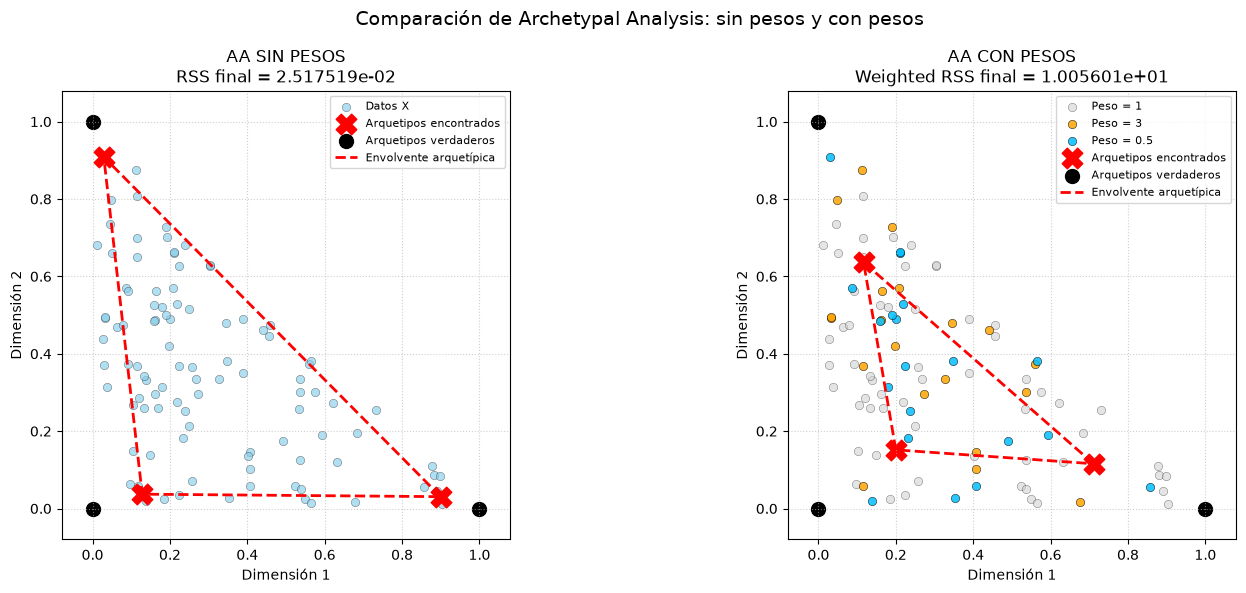


COMPARACIÓN DE RESULTADOS

Arquetipos verdaderos:
[[0. 0.]
 [1. 0.]
 [0. 1.]]

Arquetipos encontrados SIN pesos:
[[0.89972533 0.03070263]
 [0.02894368 0.90875589]
 [0.12834471 0.03711885]]

Arquetipos encontrados CON pesos:
[[0.7110226  0.11574249]
 [0.11651955 0.63676185]
 [0.19997441 0.1517004 ]]

RSS sin pesos:
0.02517519307132474

RSS ponderado:
10.056011184403639


In [35]:

# ============================================================
# PRUEBA Y DIBUJO: AA SIN PESOS VS AA CON PESOS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Crear datos sintéticos con 3 arquetipos verdaderos
# ------------------------------------------------------------

rng = np.random.default_rng(42)

true_Z = np.array([
    [0.0, 0.0],
    [1.0, 0.0],
    [0.0, 1.0]
])

n_samples = 100

true_S = rng.dirichlet(
    np.ones(3),
    size=n_samples
)

X = true_S @ true_Z

# ------------------------------------------------------------
# 2. Definir pesos por observación
# ------------------------------------------------------------
# Ejemplo: damos más importancia a las primeras observaciones.
# Cambia estos valores si quieres estudiar otro escenario.

weights = np.ones(n_samples)
weights[:20] = 3.0
weights[20:40] = 0.5

# ------------------------------------------------------------
# 3. Ejecutar AA SIN PESOS
# ------------------------------------------------------------

C_unweighted, S_unweighted, Z_unweighted, history_unweighted, selected_unweighted = (
    archetypal_analysis(
        X,
        p=3,
        max_iter=100,
        max_inner_iter=10,
        tol=1e-8,
        random_state=42,
        verbose=False
    )
)

# ------------------------------------------------------------
# 4. Ejecutar AA CON PESOS
# ------------------------------------------------------------

C_weighted, S_weighted, Z_weighted, history_weighted, selected_weighted, weights_out = (
    weighted_archetypal_analysis(
        X=X,
        p=3,
        weights=weights,
        max_iter=100,
        max_inner_iter=10,
        tol=1e-8,
        random_state=42,
        verbose=False,
        furthest_sum_func=furthest_sum,
        initialize_C_func=initialize_C,
        initialize_S_func=initialize_S,
        compute_archetypes_func=compute_archetypes
    )
)

# ------------------------------------------------------------
# 5. Dibujar ambos resultados
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Observaciones con pesos elevados
high_weight = weights > 1.0

# Observaciones con pesos bajos
low_weight = weights < 1.0

# ============================================================
# PANEL IZQUIERDO: SIN PESOS
# ============================================================

ax = axes[0]

ax.scatter(
    X[:, 0], X[:, 1],
    c="skyblue",
    alpha=0.65,
    edgecolors="k",
    linewidths=0.3,
    label="Datos X"
)

ax.scatter(
    Z_unweighted[:, 0], Z_unweighted[:, 1],
    c="red",
    s=220,
    marker="X",
    label="Arquetipos encontrados"
)

ax.scatter(
    true_Z[:, 0], true_Z[:, 1],
    c="black",
    s=100,
    marker="o",
    label="Arquetipos verdaderos"
)

Z_polygon_unweighted = np.vstack([
    Z_unweighted,
    Z_unweighted[0]
])

ax.plot(
    Z_polygon_unweighted[:, 0],
    Z_polygon_unweighted[:, 1],
    "r--",
    linewidth=2,
    label="Envolvente arquetípica"
)

ax.set_title(
    "AA SIN PESOS\n"
    f"RSS final = {history_unweighted[-1]:.6e}"
)

ax.set_xlabel("Dimensión 1")
ax.set_ylabel("Dimensión 2")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=8)


# ============================================================
# PANEL DERECHO: CON PESOS
# ============================================================

ax = axes[1]

# Observaciones de peso normal
ax.scatter(
    X[~high_weight & ~low_weight, 0],
    X[~high_weight & ~low_weight, 1],
    c="lightgray",
    alpha=0.6,
    edgecolors="k",
    linewidths=0.3,
    label="Peso = 1"
)

# Observaciones de peso elevado
ax.scatter(
    X[high_weight, 0],
    X[high_weight, 1],
    c="orange",
    alpha=0.85,
    edgecolors="k",
    linewidths=0.4,
    label="Peso = 3"
)

# Observaciones de peso reducido
ax.scatter(
    X[low_weight, 0],
    X[low_weight, 1],
    c="deepskyblue",
    alpha=0.85,
    edgecolors="k",
    linewidths=0.4,
    label="Peso = 0.5"
)

ax.scatter(
    Z_weighted[:, 0], Z_weighted[:, 1],
    c="red",
    s=220,
    marker="X",
    label="Arquetipos encontrados"
)

ax.scatter(
    true_Z[:, 0], true_Z[:, 1],
    c="black",
    s=100,
    marker="o",
    label="Arquetipos verdaderos"
)

Z_polygon_weighted = np.vstack([
    Z_weighted,
    Z_weighted[0]
])

ax.plot(
    Z_polygon_weighted[:, 0],
    Z_polygon_weighted[:, 1],
    "r--",
    linewidth=2,
    label="Envolvente arquetípica"
)

ax.set_title(
    "AA CON PESOS\n"
    f"Weighted RSS final = {history_weighted[-1]:.6e}"
)

ax.set_xlabel("Dimensión 1")
ax.set_ylabel("Dimensión 2")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=8)

# Mantener la misma escala en ambos paneles
for ax in axes:
    ax.set_xlim(-0.08, 1.08)
    ax.set_ylim(-0.08, 1.08)
    ax.set_aspect("equal", adjustable="box")

fig.suptitle(
    "Comparación de Archetypal Analysis: sin pesos y con pesos",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Comparación numérica
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("COMPARACIÓN DE RESULTADOS")
print("=" * 65)

print("\nArquetipos verdaderos:")
print(true_Z)

print("\nArquetipos encontrados SIN pesos:")
print(Z_unweighted)

print("\nArquetipos encontrados CON pesos:")
print(Z_weighted)

print("\nRSS sin pesos:")
print(np.sum((X - S_unweighted @ C_unweighted @ X) ** 2))

print("\nRSS ponderado:")
print(np.sum(
    (weights[:, None] *
     (X - S_weighted @ C_weighted @ X)) ** 2
))